# Лабораторная работа 4 - Метод главных компонент (PCA)

На основе варианта создать датасет.

Вариант 2, $N = 1000$:

- $X_1$ - равномерно от 0 до 10
- $X_2$ - равномерно от 0 до 10
- $X_3 = X_1 + X_2 + \varepsilon$, где $\varepsilon$ - нормальный шум со средним 0 и дисперсией 5
- $X_4$ - нормально со средним 10 и дисперсией 9
- $X_5 = 2X_4 + \varepsilon$, где $\varepsilon$ - нормальный шум со средним 1 и дисперсией 3
- $X_6$ - экспоненциально с $\lambda = 0.5$
- $X_7 = \sqrt{X_6}$
- $X_8$ - бинарная переменная со значениями 0 или 1, закон распределения равномерный

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng()

N = 1000
X1 = rng.uniform(0, 10, N)
X2 = rng.uniform(0, 10, N)
#                  normal принимает стандартное отклонение, вместо дисперсии. sigma = D ** 0.5
X3 = X1 + X2 + rng.normal(0, np.sqrt(5), N)
X4 = rng.normal(10, np.sqrt(9), N)
X5 = 2 * X4 + rng.normal(1, np.sqrt(3), N)
X6 = rng.exponential(1 / 0.5, N)
X7 = np.sqrt(X6)
X8 = rng.integers(0, 2, N)

df = pd.DataFrame({
    "X1": X1,
    "X2": X2,
    "X3": X3,
    "X4": X4,
    "X5": X5,
    "X6": X6,
    "X7": X7,
    "X8": X8
})
X = df.values

Найти коэффициент корреляции между всеми столбцами

$$r_{xy} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

Если столбцы стандартизировать, то вся матрица корреляций считается одним умножением:

$$R = \frac{1}{N} Z^T Z$$

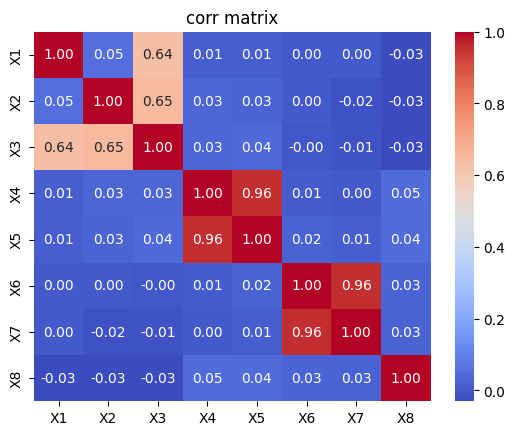

In [3]:
def mean(x, axis=0):
    return np.sum(x, axis=axis) / len(x)

def var(x, axis=0):
    m = mean(x, axis)
    return np.sum((x - m) ** 2, axis) / len(x)

def std(x, axis=0):
    return var(x, axis) ** 0.5

def corr_matrix(data):
    Z = (data - mean(data, axis=0)) / std(data, axis=0)
    return Z.T @ Z / len(data)


R = corr_matrix(X)

sns.heatmap(R, annot=True, fmt='.2f', xticklabels=df.columns, yticklabels=df.columns, cmap='coolwarm')
plt.title('corr matrix')
plt.show()


Реализовать алгоритм PCA на основе сингулярного разложения (SVD)

Готовый SVD использовать нельзя. Из работы с матрицами разрешены только сложение, умножение и создание единичной матрицы.

$$A = U \Sigma V^T$$

Столбцы $V$ - собственные векторы $A^T A$. Находим их степенным методом:

$$v \leftarrow \frac{Mv}{\lVert Mv \rVert}, \qquad M = A^T A$$

Потом считаем $\sigma = \lVert Av \rVert$ и $u = Av / \sigma$, снимаем найденный слой и повторяем:

$$A \leftarrow A - \sigma u v^T$$

In [4]:
def norm(v):
    return (v @ v) ** 0.5

def top_vector(M, eps=1e-12, max_iter=20_000):
    v = rng.random(M.shape[0])
    v = v / norm(v)

    for _ in range(max_iter):
        w = M @ v
        w = w / norm(w)
        if norm(w - v) < eps:
            return w

        v = w

    return v

def svd(A, k):
    U, S, V = [], [], []
    for _ in range(k):
        M = A.T @ A
        v = top_vector(M)
        s = norm(A @ v)
        u = A @ v / s

        U.append(u)
        S.append(s)
        V.append(v)

        A = A - s * np.outer(u, v)

    return np.array(U).T, np.array(S), np.array(V).T


A = X - mean(X)
U, S, V = svd(A, 8)

print(f"our sigma: {S.round(4)}")
print(f"svd sigma: {np.linalg.svd(A, compute_uv=False).round(4)}")

our sigma: [218.0078 171.1704  88.4239  65.1729  37.4639  24.5594  15.7596   5.651 ]
svd sigma: [218.0078 171.1704  88.4239  65.1729  37.4639  24.5594  15.7596   5.651 ]


PCA: центрируем данные, делаем SVD, проецируем на столбцы $V$

$$P = AV = U\Sigma, \qquad \lambda_i = \frac{\sigma_i^2}{N - 1}$$

In [8]:
def pca(data, k):
    m = mean(data, axis=0)
    A = data - m
    U, S, V = svd(A, k)
    return A @ V, S ** 2 / (len(data) - 1), V, m

P, lam, V2, m = pca(X, 2)
print(f"собственные значения: {lam.round(4)}")

собственные значения: [47.575  29.3286]


Найти проекцию датасета на 2-мерную систему координат

Найти ошибку проекции датасета

Восстанавливаем данные из проекции и смотрим, какая доля разброса потерялась:

$$\hat{A} = P V^T, \qquad error = \frac{\sum (A - \hat{A})^2}{\sum A^2} = \frac{\sum_{j > k} \lambda_j}{\sum_j \lambda_j}$$

In [10]:
def projection_error(data, k):
    P, _, V, m = pca(data, k)
    A = data - m
    A_proj = P @ V.T
    return np.sum((A - A_proj) ** 2) / np.sum(A ** 2)

print(f"ошибка на 2д: {projection_error(X, 2)}")

ошибка на 2д: 0.1574172114494696


Найти преобразование входных данных, при котором ошибка проекции будет оптимальной. Провести эксперимент по поиску числа компонент, при котором ошибка сжатия допустима

Сравним исходные данные и стандартизированные:

$$z = \frac{x - \bar{x}}{s}$$

Допустимой будем считать ошибку 5%.

Сколько разброса каждого признака осталось после сжатия: общая ошибка могла быть маленькой, а отдельный признак мог потеряться целиком

Ошибка зависит от единиц измерения: запишем $X_8$ как 0 и 100 вместо 0 и 1

Вопросы 2 и 5. Нелинейные данные: точки лежат на кольце. По сути это одна величина, угол, но прямая её не опишет

Вопросы 2 и 7. Выбросы: добавим 5 точек с огромным $X_6$ и посмотрим, куда повернётся первая компонента

Вопрос 6. Что теряется при малом числе компонент: сожмём картинки рукописных цифр 8x8 (64 признака) и восстановим обратно

Вопрос 8. PCA перед обучением модели: предсказываем $y$ линейной регрессией по компонентам

Среднее, отклонение и компоненты считаем только на обучающей части, тестовую просто пропускаем через готовое преобразование